Homework 7, problem 1, parts c and d

In [1]:
# libraries and parameters

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import cauchy

np.random.seed(42)
true_alpha, true_beta = 1.5, 0.8
n_data_c = 200
x_data_c = np.random.standard_cauchy(n_data_c) * true_beta + true_alpha # dataset for part c

Part c

In [2]:
def log_posterior(theta, x):
    """
    Computes unnormalized log-posterior. 
    Assumes a flat/uniform prior for alpha and beta (with beta > 0 constraint).
    """
    alpha, beta = theta[0], theta[1]
    if beta <= 0:
        return -np.inf
    # sum of log-likelihoods for Cauchy distribution
    return np.sum(np.log(beta) - np.log(np.pi * (beta**2 + (x - alpha)**2)))

def compute_iact(series, max_lag=1000):
    """
    Computes the Integrated Autocorrelation Time (IACT) using Sokal's adaptive window approach.
    """
    n = len(series)
    series_norm = series - np.mean(series)
    # fast autocorrelation
    f = np.fft.fft(series_norm, n=2*n)
    acf = np.fft.ifft(f * np.conjugate(f))[:n].real
    acf /= acf[0]
    
    # sum up to an adaptive window where lag > 5 * tau
    tau = 0.5
    for lag in range(1, max_lag):
        tau += acf[lag]
        if lag > 5 * (2 * tau):
            break
    return 2 * tau

In [3]:
# simulation parameters
T = 50000
step_sizes = [0.02, 0.5, 5]
chains = {}
acceptance_rates = {}
iact_values = {}

# MCMC
for s in step_sizes:
    chain = np.zeros((T, 2))
    current_state = np.array([0.0, 0.5])  # start at (0, 0) for alpha, small positive for beta
    current_log_post = log_posterior(current_state, x_data_c)
    accepted = 0
    
    for t in range(T):
        # propose symmetric Gaussian step with standard deviation s
        proposal = current_state + np.random.normal(0, s, size=2)
        proposal_log_post = log_posterior(proposal, x_data_c)
        
        # metropolis acceptance criterion
        if np.log(np.random.uniform(0, 1)) < (proposal_log_post - current_log_post):
            current_state = proposal
            current_log_post = proposal_log_post
            accepted += 1
            
        chain[t] = current_state
        
    chains[s] = chain
    acceptance_rates[s] = accepted / T
    iact_values[s] = compute_iact(chain[:, 0])

Part c metrics
Step size s = 0.02 | Acceptance Rate: 0.8681 | IACT of alpha: 127.55
Step size s = 0.5  | Acceptance Rate: 0.0443 | IACT of alpha: 40.14
Step size s = 5    | Acceptance Rate: 0.0008 | IACT of alpha: 831.32


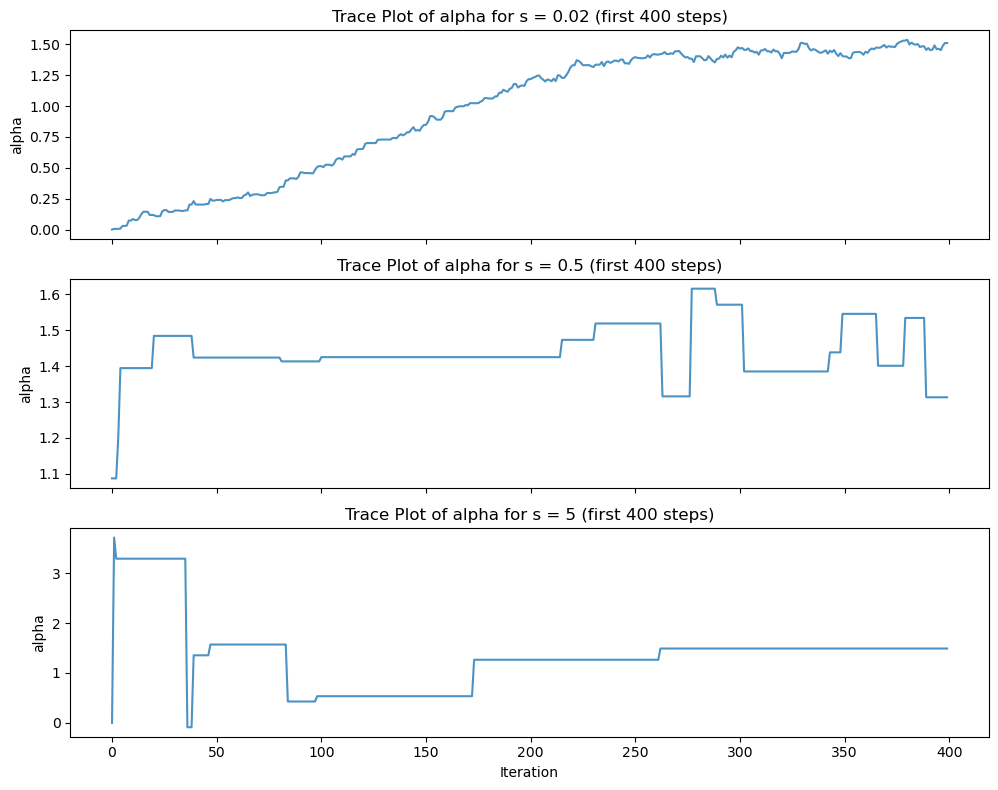

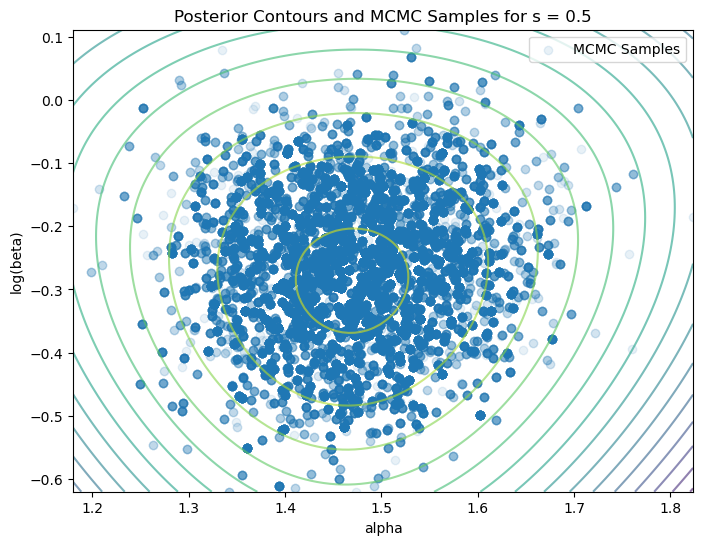

Posterior comparisons
Chain Mean: alpha = 1.4716, beta = 0.7686
Chain 90% CI: alpha = [1.3485, 1.6022], beta = [0.6337, 0.8998]
Grid Mean: alpha = 1.4701, beta = 0.7679
Grid 90% CI: alpha = [1.3490, 1.5895], beta = [0.6433, 0.9068]
Data Sample Mean: 2.3848
Data Sample Median: 1.4607


In [4]:
print("Part c metrics")
for s in step_sizes:
    print(f"Step size s = {s:<4} | Acceptance Rate: {acceptance_rates[s]:.4f} | IACT of alpha: {iact_values[s]:.2f}")

# plot first 400 trace values for each s
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for i, s in enumerate(step_sizes):
    axes[i].plot(chains[s][:400, 0], alpha=0.8)
    axes[i].set_title(f"Trace Plot of alpha for s = {s} (first 400 steps)")
    axes[i].set_ylabel("alpha")
axes[-1].set_xlabel("Iteration")
plt.tight_layout()
plt.show()

# analysis of the "Best s" (s = 0.5)
best_s = 0.5
burn_in = 5000
clean_chain = chains[best_s][burn_in:]

alpha_samples = clean_chain[:, 0]
beta_samples = clean_chain[:, 1]
log_beta_samples = np.log(beta_samples)

# grid evaluation for exact posterior
alpha_grid = np.linspace(min(alpha_samples), max(alpha_samples), 100)
beta_grid = np.linspace(max(0.1, min(beta_samples)), max(beta_samples), 100)
A, B = np.meshgrid(alpha_grid, beta_grid)

Z = np.zeros_like(A)
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        Z[i, j] = np.exp(log_posterior([A[i, j], B[i, j]], x_data_c))
# normalize the grid posterior density
Z /= np.sum(Z) * (alpha_grid[1] - alpha_grid[0]) * (beta_grid[1] - beta_grid[0])

plt.figure(figsize=(8, 6))
plt.contour(A, np.log(B), np.log(Z), levels=15, alpha=0.6)
plt.scatter(alpha_samples, log_beta_samples, alpha=0.1, label = 'MCMC Samples')
plt.title(f"Posterior Contours and MCMC Samples for s = {best_s}")
plt.xlabel("alpha")
plt.ylabel("log(beta)")
plt.legend()
plt.show()

# summary statistics
chain_mean_alpha, chain_mean_beta = np.mean(alpha_samples), np.mean(beta_samples)
chain_ci_alpha = np.percentile(alpha_samples, [5, 95])
chain_ci_beta = np.percentile(beta_samples, [5, 95])

# marginal expectations
p_alpha = np.sum(Z, axis=0) * (beta_grid[1] - beta_grid[0])
p_beta = np.sum(Z, axis=1) * (alpha_grid[1] - alpha_grid[0])
p_alpha /= np.sum(p_alpha)
p_beta /= np.sum(p_beta)

grid_mean_alpha = np.sum(alpha_grid * p_alpha)
grid_mean_beta = np.sum(beta_grid * p_beta)

# cumulative distribution functions for grid quantiles
cdf_alpha = np.cumsum(p_alpha)
cdf_beta = np.cumsum(p_beta)
grid_ci_alpha = [alpha_grid[np.searchsorted(cdf_alpha, 0.05)], alpha_grid[np.searchsorted(cdf_alpha, 0.95)]]
grid_ci_beta = [beta_grid[np.searchsorted(cdf_beta, 0.05)], beta_grid[np.searchsorted(cdf_beta, 0.95)]]

print("Posterior comparisons")
print(f"Chain Mean: alpha = {chain_mean_alpha:.4f}, beta = {chain_mean_beta:.4f}")
print(f"Chain 90% CI: alpha = [{chain_ci_alpha[0]:.4f}, {chain_ci_alpha[1]:.4f}], beta = [{chain_ci_beta[0]:.4f}, {chain_ci_beta[1]:.4f}]")
print(f"Grid Mean: alpha = {grid_mean_alpha:.4f}, beta = {grid_mean_beta:.4f}")
print(f"Grid 90% CI: alpha = [{grid_ci_alpha[0]:.4f}, {grid_ci_alpha[1]:.4f}], beta = [{grid_ci_beta[0]:.4f}, {grid_ci_beta[1]:.4f}]")
print(f"Data Sample Mean: {np.mean(x_data_c):.4f}")
print(f"Data Sample Median: {np.median(x_data_c):.4f}")

Part d

In [5]:
n_datasets = 2000
sample_sizes = [10, 100, 1000]
alpha_true, beta_true = 1.5, 0.8

results = {}

for n in sample_sizes:
    # fully vectorized generation: (2000 datasets, n samples each)
    samples = np.random.standard_cauchy((n_datasets, n)) * beta_true + alpha_true
    
    means = np.mean(samples, axis=1)
    medians = np.median(samples, axis=1)
    
    # compute standardized scatter via IQR / 1.349
    scatter_mean = (np.percentile(means, 75) - np.percentile(means, 25)) / 1.349
    scatter_median = (np.percentile(medians, 75) - np.percentile(medians, 25)) / 1.349
    
    results[n] = {'scatter_mean': scatter_mean, 'scatter_median': scatter_median}

print(f"{'n':<6} | {'Sample Mean Scatter':<20} | {'Sample Median Scatter':<20}")
for n in sample_sizes:
    print(f"{n:<6} | {results[n]['scatter_mean']:<20.4f} | {results[n]['scatter_median']:<20.4f}")


n      | Sample Mean Scatter  | Sample Median Scatter
10     | 1.2771               | 0.3912              
100    | 1.1968               | 0.1254              
1000   | 1.1632               | 0.0391              
